In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0061665645688748745 - 0.003489994096732982im -0.0015954797797195332 + 0.001129292721619462im … 0.0012404669410320415 - 0.0033133914971644517im -0.001309127826407684 - 0.000634439386862133im; -0.0033613519248025005 + 0.007803960447601892im -0.003805692543705081 + 0.0019841895977454806im … -0.0011718470361174883 + 0.0031093104158961857im -0.0018672557364354592 - 0.0012798205391206978im; 0.0061259183398202025 - 0.0029302331869297377im -0.002333638192730394 - 0.0003005284572709686im … 0.000757897601597467 - 0.0011398812131053662im -0.002448640666402104 + 0.0018351698157372323im;;; -0.005416091526908201 + 0.004224260733502293im -0.0015365944122456324 + 0.0036037537439279985im … -0.000997303071889812 + 0.00838640987300009im -0.0045543907407037225 - 0.0002330225307087269im; 0.0014429389039950992 + 0.001316973552757252im 0.0023792416109664413 + 0.0013119432746134321im … -0.0020509433473944543 + 0.0034689501032629743i

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)
W2=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [0.5271021084743945 + 0.0im 0.7085727737564367 + 0.0im -1.1247809009336278 + 0.0im 0.055170273476560096 + 0.0im; -0.4540463657121832 + 0.0im -0.6138922871177349 + 0.0im 1.543879112475843 + 0.0im -1.7213706794735149 + 0.0im; 0.03540554955458161 + 0.0im -0.6602083007426682 + 0.0im 0.43233333882338737 + 0.0im -2.7447254140973802 + 0.0im; 0.21237446012038638 + 0.0im -0.19836935059679242 + 0.0im 1.627497948721245 + 0.0im -1.5807616791443926 + 0.0im]
 [-0.0003568049849413505 + 0.0im -1.7502489913033334 + 0.0im 0.05480187002954921 + 0.0im 0.6262155852016618 + 0.0im; 1.204319808324807 + 0.0im 0.6235371196751756 + 0.0im -1.7410067963260323 + 0.0im -1.6448614024616388 + 0.0im; -0.11495623308611035 + 0.0im -1.2693270977383393 + 0.0im 0.042438337575001935 + 0.0im -1.1338563301628626 + 0.0im; 0.880429280710184 + 0.0im -0.621890560347234 + 0.0im 0.7982687662833018 + 0.0im 0.4631018278711104 + 0.0im]
 [-1.0376848210385057 + 0.0im 0.660136801603284 + 0.0im 0.50528794804

In [4]:
# layer1=CPTC_Layer(hop,W1)
# Norm=NormLayer()
# layer2=PTC_Layer(hop,W2)
# act=Softmax()
# layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
# layers=[layer1,Norm,layer2]

In [5]:
opt=Adam()
opt.α=0.05

0.05

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-7.062361696031111e-6 + 7.18224234249649e-6im -2.6909099955724264e-6 + 1.7626177656894798e-6im … 1.5460006276242761e-6 + 2.8381974401055473e-6im -2.689345688365466e-6 - 4.344780530363615e-6im; 1.0594009092632211e-5 - 1.0950476548389792e-5im -6.241702613668146e-6 + 5.0627265400018905e-6im … -2.817579334382343e-7 + 8.782603051449635e-7im 5.690343336911002e-7 + 2.0090452771213446e-6im; 5.5009211804403134e-6 + 2.7362512271441385e-6im -4.446899997339529e-6 + 9.311505670433934e-6im … 2.5936799638841797e-6 + 2.5673851277262263e-6im 3.986882278391503e-6 + 1.653806285116222e-5im;;; 5.07095722332264e-6 + 8.76021454728829e-6im -6.30968613512774e-7 - 2.6129725589136597e-6im … 1.5150409594196086e-6 - 5.6648215059635406e-6im 6.271542921880829e-7 - 5.9911767182062745e-6im; 1.1337651753664989e-5 - 5.290425182932344e-6im 4.888119287771785e-6 - 2.8115021126877155e-6im … 8.853822530493038e-6 - 7.871537320140951e-7im 5.92680688370

In [7]:
# @load "PTC_weight.jld2" W
# layer2.W=W
# layer1.V.W=W

In [8]:
# println(typeof((-1)*Matmul!(x,x)))

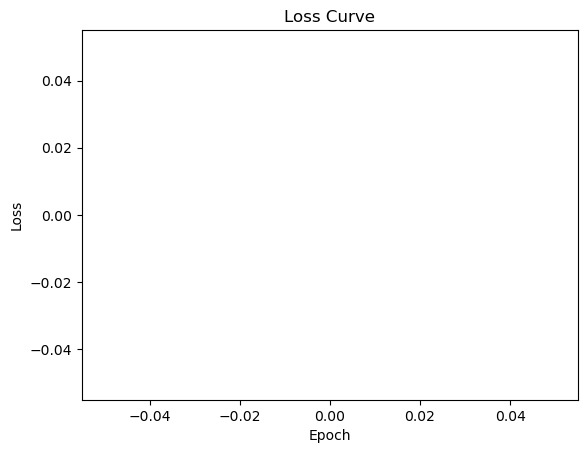

Epoch: 1, Loss: 0.24863211998955645 + 0.0im
Epoch: 2, Loss: 0.36411983910828555 + 0.0im
Epoch: 3, Loss: 0.16139529828634577 + 0.0im
Epoch: 4, Loss: 0.1389810245672444 + 0.0im
Epoch: 5, Loss: 0.1857740586931888 + 0.0im
Epoch: 6, Loss: 0.18834910528778034 + 0.0im
Epoch: 7, Loss: 0.1600492839872334 + 0.0im
Epoch: 8, Loss: 0.13154261541743478 + 0.0im
Epoch: 9, Loss: 0.11799262581728173 + 0.0im
Epoch: 10, Loss: 0.10990597667320032 + 0.0im
Epoch: 11, Loss: 0.10460198941314322 + 0.0im
Epoch: 12, Loss: 0.10199888666452057 + 0.0im
Epoch: 13, Loss: 0.09853905789656844 + 0.0im
Epoch: 14, Loss: 0.08930454812601628 + 0.0im
Epoch: 15, Loss: 0.08098300069903355 + 0.0im
Epoch: 16, Loss: 0.0800285296887263 + 0.0im
Epoch: 17, Loss: 0.08249162825682992 + 0.0im
Epoch: 18, Loss: 0.08293594505444263 + 0.0im
Epoch: 19, Loss: 0.07974748755928582 + 0.0im
Epoch: 20, Loss: 0.07384450525446987 + 0.0im
Epoch: 21, Loss: 0.06854212503414332 + 0.0im
Epoch: 22, Loss: 0.06526937691329993 + 0.0im
Epoch: 23, Loss: 0.0627

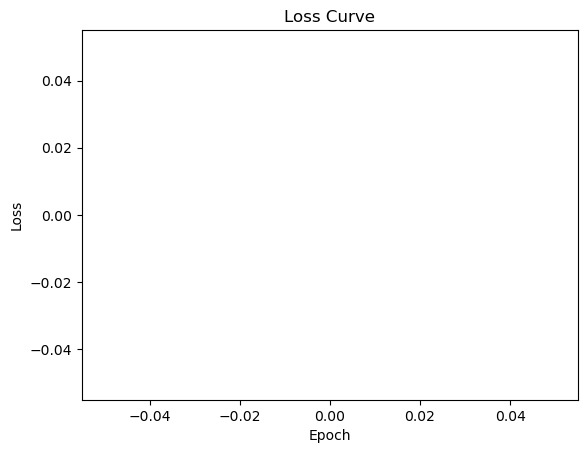

Epoch: 1, Loss: 0.24027415628681922 + 0.0im
Epoch: 2, Loss: 0.6897701895988904 + 0.0im
Epoch: 3, Loss: 0.4044764392994193 + 0.0im
Epoch: 4, Loss: 0.5035937772251103 + 0.0im
Epoch: 5, Loss: 0.5139415716944473 + 0.0im
Epoch: 6, Loss: 0.49208680008350697 + 0.0im
Epoch: 7, Loss: 0.5618292555503293 + 0.0im
Epoch: 8, Loss: 0.5618018975160166 + 0.0im
Epoch: 9, Loss: 0.5264171237734625 + 0.0im
Epoch: 10, Loss: 0.5033174480712539 + 0.0im
Epoch: 11, Loss: 0.503613287135171 + 0.0im
Epoch: 12, Loss: 0.4645396858448197 + 0.0im
Epoch: 13, Loss: 0.4714539070891632 + 0.0im
Epoch: 14, Loss: 0.4774240348415773 + 0.0im
Epoch: 15, Loss: 0.45708951104844353 + 0.0im
Epoch: 16, Loss: 0.44885778033472024 + 0.0im
Epoch: 17, Loss: 0.4357733884063719 + 0.0im
Epoch: 18, Loss: 0.41322566043729636 + 0.0im
Epoch: 19, Loss: 0.4011740423399794 + 0.0im
Epoch: 20, Loss: 0.39625286593170955 + 0.0im
Epoch: 21, Loss: 0.38363929271434866 + 0.0im
Epoch: 22, Loss: 0.37409630732486204 + 0.0im
Epoch: 23, Loss: 0.353626759389084

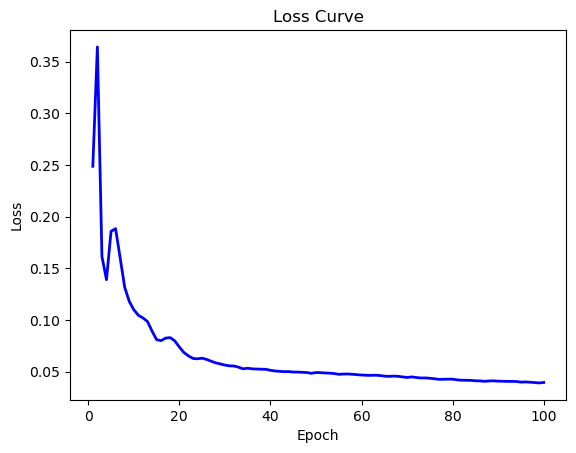

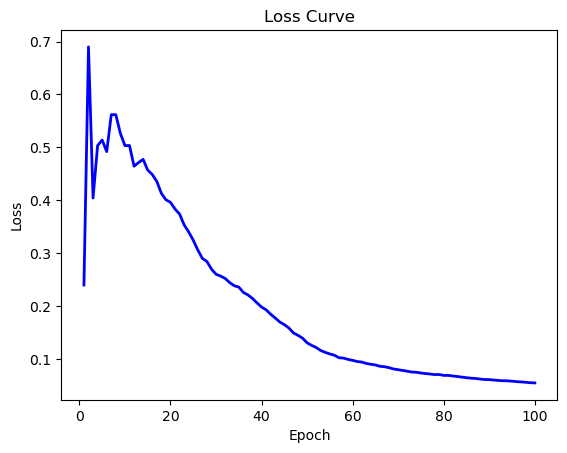

In [9]:
for i in (0.01,0.001)
    
    layer1=CPTC_Layer(hop,deepcopy(W1))
    Norm=NormLayer()
    layer2=PTC_Layer(hop,deepcopy(W2))
    act=Softmax()
    layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
    layers=[layer1,Norm,layer2]

    layer1.V.W = layer1.V.W*i
    layer1.K.W = layer1.K.W*i
    layer1.Q.W = layer1.Q.W*i
    layer2.W = layer2.W*i
    train(opt,layers,x,t,D,epochs=100)
end 

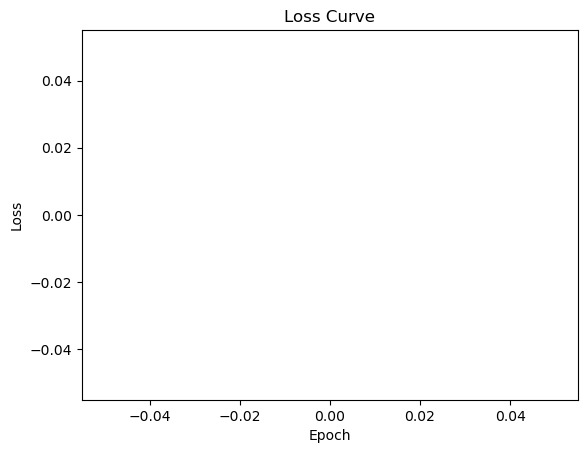

Epoch: 1, Loss: 0.24701883431240762 + 0.0im
Epoch: 2, Loss: 1.5673243362391005 + 0.0im
Epoch: 3, Loss: 0.3946879349430511 + 0.0im
Epoch: 4, Loss: 0.987255110972757 + 0.0im
Epoch: 5, Loss: 0.8118454243153107 + 0.0im
Epoch: 6, Loss: 0.6368716117997545 + 0.0im
Epoch: 7, Loss: 0.677459180241477 + 0.0im
Epoch: 8, Loss: 0.5404071387109518 + 0.0im
Epoch: 9, Loss: 0.36343925993174453 + 0.0im
Epoch: 10, Loss: 0.4078058994392345 + 0.0im
Epoch: 11, Loss: 0.3825866312217279 + 0.0im
Epoch: 12, Loss: 0.33216918993227396 + 0.0im
Epoch: 13, Loss: 0.3353640401939518 + 0.0im
Epoch: 14, Loss: 0.307657890940311 + 0.0im
Epoch: 15, Loss: 0.24894559316709403 + 0.0im
Epoch: 16, Loss: 0.22326849994207693 + 0.0im
Epoch: 17, Loss: 0.21402364513578345 + 0.0im
Epoch: 18, Loss: 0.21542756053049095 + 0.0im
Epoch: 19, Loss: 0.19718243321768952 + 0.0im
Epoch: 20, Loss: 0.17492325730751365 + 0.0im
Epoch: 21, Loss: 0.16059929170068848 + 0.0im
Epoch: 22, Loss: 0.14169371873397854 + 0.0im
Epoch: 23, Loss: 0.12476459577018

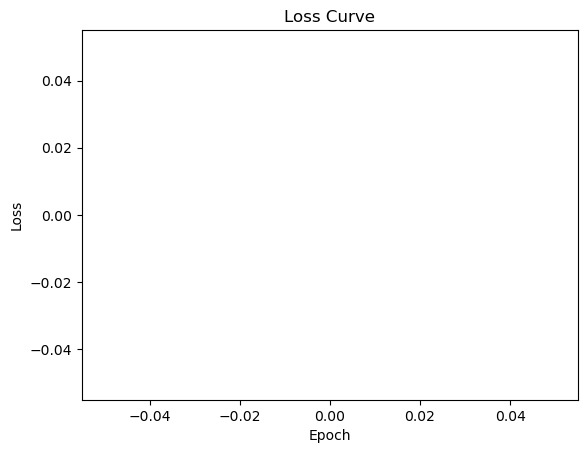

Epoch: 1, Loss: 0.242660610961734 + 0.0im
Epoch: 2, Loss: 2.23757473011349 + 0.0im
Epoch: 3, Loss: 0.6747559585997401 + 0.0im
Epoch: 4, Loss: 3.120407445015392 + 0.0im
Epoch: 5, Loss: 1.1456063609772464 + 0.0im
Epoch: 6, Loss: 1.2904574677080158 + 0.0im
Epoch: 7, Loss: 1.1466394156163542 + 0.0im
Epoch: 8, Loss: 1.0523439047541103 + 0.0im
Epoch: 9, Loss: 0.9914663491474569 + 0.0im
Epoch: 10, Loss: 1.0885182238361906 + 0.0im
Epoch: 11, Loss: 1.125903601418625 + 0.0im
Epoch: 12, Loss: 0.7743347439509457 + 0.0im
Epoch: 13, Loss: 0.7596857991328252 + 0.0im
Epoch: 14, Loss: 0.5703420105678849 + 0.0im
Epoch: 15, Loss: 0.5432187974796998 + 0.0im
Epoch: 16, Loss: 0.5690575333921007 + 0.0im
Epoch: 17, Loss: 0.49864882042521497 + 0.0im
Epoch: 18, Loss: 0.39355421808923047 + 0.0im
Epoch: 19, Loss: 0.35182474376258654 + 0.0im
Epoch: 20, Loss: 0.3605000224627875 + 0.0im
Epoch: 21, Loss: 0.32829550116249095 + 0.0im
Epoch: 22, Loss: 0.2949026682301 + 0.0im
Epoch: 23, Loss: 0.27987935427817323 + 0.0im


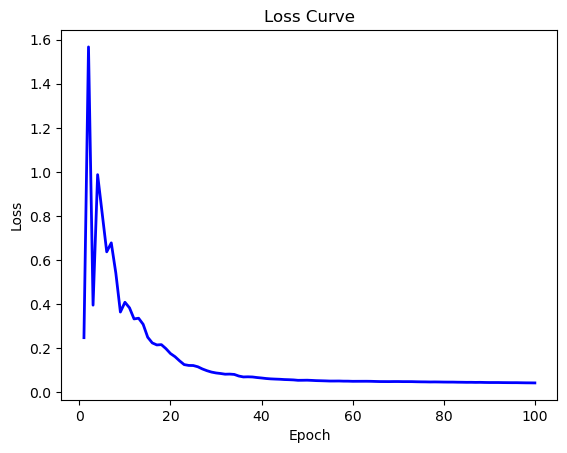

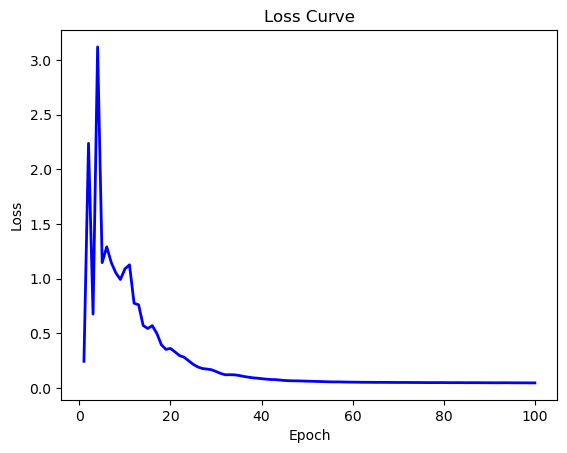

In [12]:
for i in (0.1,0.01,0.001)
    
    layer1=CPTC_Layer(hop,deepcopy(W1))
    Norm=complexNormLayer()
    layer2=PTC_Layer(hop,deepcopy(W2))
    act=Softmax()
    layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
    layers=[layer1,Norm,layer2]

    layer1.V.W = layer1.V.W*i
    layer1.K.W = layer1.K.W*i
    layer1.Q.W = layer1.Q.W*i
    layer2.W = layer2.W*i
    train(opt,layers,x,t,D,epochs=100)
end 

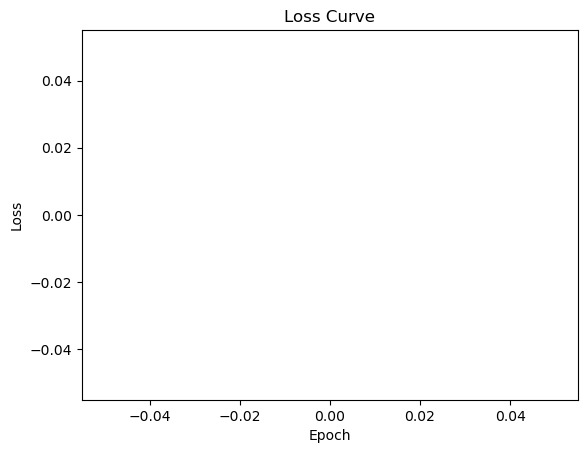

Epoch: 1, Loss: 0.7348528817083748 + 0.0im
Epoch: 2, Loss: 1.163635051321724 + 0.0im
Epoch: 3, Loss: 1.3517581645915946 + 0.0im
Epoch: 4, Loss: 1.0302906838981296 + 0.0im
Epoch: 5, Loss: 1.2677223840741068 + 0.0im
Epoch: 6, Loss: 1.104617710960065 + 0.0im
Epoch: 7, Loss: 0.8904405178725983 + 0.0im
Epoch: 8, Loss: 0.9765585077763883 + 0.0im
Epoch: 9, Loss: 0.9832899467008666 + 0.0im
Epoch: 10, Loss: 0.8456370164648441 + 0.0im
Epoch: 11, Loss: 0.804528592611995 + 0.0im
Epoch: 12, Loss: 0.8215275626190249 + 0.0im
Epoch: 13, Loss: 0.7953287354291383 + 0.0im
Epoch: 14, Loss: 0.7754152119461323 + 0.0im
Epoch: 15, Loss: 0.757475196946241 + 0.0im
Epoch: 16, Loss: 0.696511465471836 + 0.0im
Epoch: 17, Loss: 0.6741728022898773 + 0.0im
Epoch: 18, Loss: 0.6999127348777463 + 0.0im
Epoch: 19, Loss: 0.704689560833159 + 0.0im
Epoch: 20, Loss: 0.6521352188896411 + 0.0im
Epoch: 21, Loss: 0.6300685199847326 + 0.0im
Epoch: 22, Loss: 0.6492387400636188 + 0.0im
Epoch: 23, Loss: 0.6412493629064093 + 0.0im
Epo

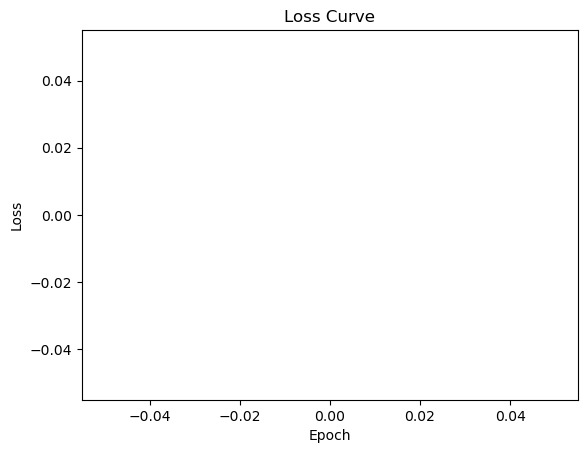

Epoch: 1, Loss: 0.2464337850806985 + 0.0im
Epoch: 2, Loss: 1.7532886137326706 + 0.0im
Epoch: 3, Loss: 1.7928142053219016 + 0.0im
Epoch: 4, Loss: 1.294135199643969 + 0.0im
Epoch: 5, Loss: 1.4778666855109488 + 0.0im
Epoch: 6, Loss: 1.489681050284473 + 0.0im
Epoch: 7, Loss: 1.3882622954543078 + 0.0im
Epoch: 8, Loss: 1.07578497922512 + 0.0im
Epoch: 9, Loss: 0.9812887099769088 + 0.0im
Epoch: 10, Loss: 1.0821647509578831 + 0.0im
Epoch: 11, Loss: 1.1216040342081905 + 0.0im
Epoch: 12, Loss: 0.9862132734108227 + 0.0im
Epoch: 13, Loss: 0.8176039826103039 + 0.0im
Epoch: 14, Loss: 0.8193895172278699 + 0.0im
Epoch: 15, Loss: 0.9011064744759291 + 0.0im
Epoch: 16, Loss: 0.8534097042347343 + 0.0im
Epoch: 17, Loss: 0.7606299847178252 + 0.0im
Epoch: 18, Loss: 0.7435648739470901 + 0.0im
Epoch: 19, Loss: 0.7460581146440037 + 0.0im
Epoch: 20, Loss: 0.7225307759456697 + 0.0im
Epoch: 21, Loss: 0.6992190576767399 + 0.0im
Epoch: 22, Loss: 0.6942940078011273 + 0.0im
Epoch: 23, Loss: 0.6836318415695483 + 0.0im
E

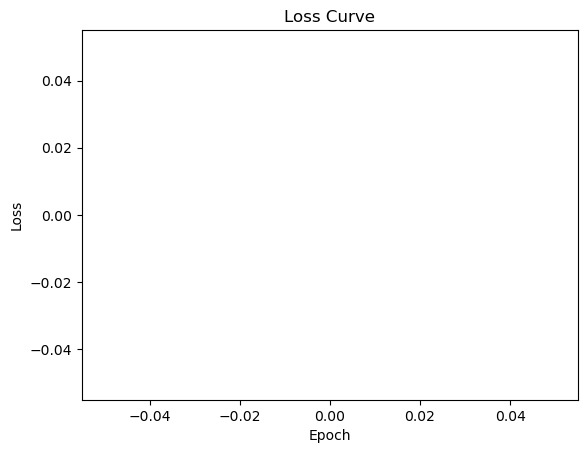

Epoch: 1, Loss: 0.24161114901246325 + 0.0im
Epoch: 2, Loss: 1.8234915733123183 + 0.0im
Epoch: 3, Loss: 1.4230161503775953 + 0.0im
Epoch: 4, Loss: 1.2823949688546465 + 0.0im
Epoch: 5, Loss: 1.5250024205747486 + 0.0im
Epoch: 6, Loss: 1.3007050691122013 + 0.0im
Epoch: 7, Loss: 1.082161458984568 + 0.0im
Epoch: 8, Loss: 1.0300910023852627 + 0.0im
Epoch: 9, Loss: 1.0593097074726145 + 0.0im
Epoch: 10, Loss: 1.0724677725823808 + 0.0im
Epoch: 11, Loss: 0.9662895817089913 + 0.0im
Epoch: 12, Loss: 0.7956242159687182 + 0.0im
Epoch: 13, Loss: 0.849226961369318 + 0.0im
Epoch: 14, Loss: 0.9023020093434988 + 0.0im
Epoch: 15, Loss: 0.8195869261809182 + 0.0im
Epoch: 16, Loss: 0.7431413302614203 + 0.0im
Epoch: 17, Loss: 0.741286150584819 + 0.0im
Epoch: 18, Loss: 0.7408182243265938 + 0.0im
Epoch: 19, Loss: 0.7160851248507055 + 0.0im
Epoch: 20, Loss: 0.7032142595268919 + 0.0im
Epoch: 21, Loss: 0.6848838653838866 + 0.0im
Epoch: 22, Loss: 0.6514350201901603 + 0.0im
Epoch: 23, Loss: 0.6527588199041466 + 0.0im

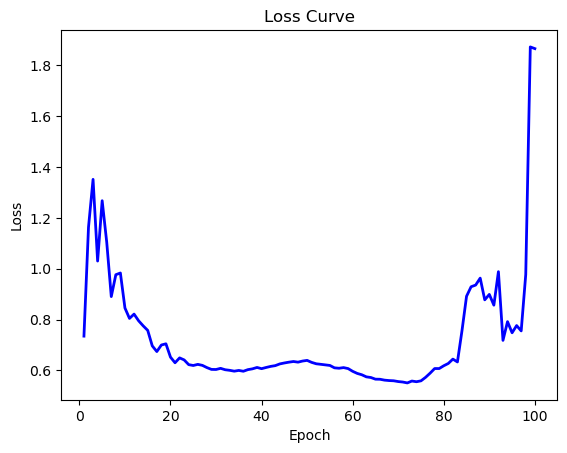

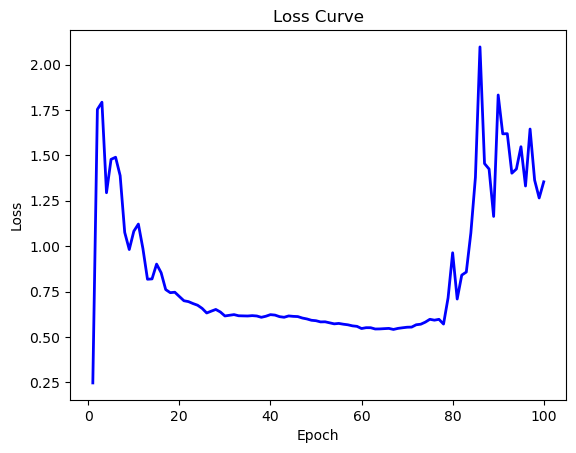

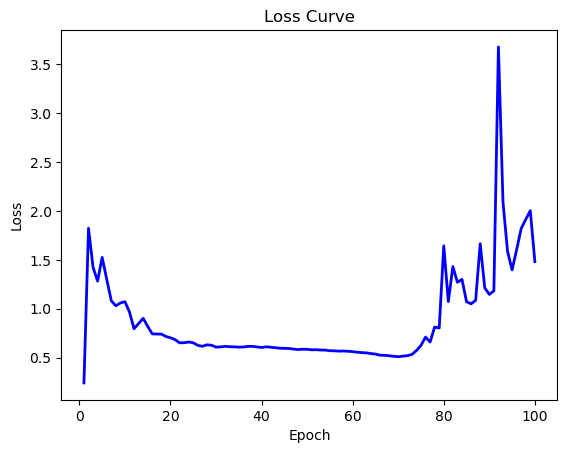

In [13]:
for i in (0.1,0.01,0.001)
    
    layer1=CPTC_Layer(hop,deepcopy(W1))
    Norm=NormLayer()
    layer2=PTC_Layer(hop,deepcopy(W2))
    act=Softmax()
    layer1=test_Layer(layer1,sqrt(length(x)),t , act,true)
    layers=[layer1,Norm,layer2]

    layer1.V.W = layer1.V.W*i
    layer1.K.W = layer1.K.W*i
    layer1.Q.W = layer1.Q.W*i
    layer2.W = layer2.W*i
    train(opt,layers,x,t,D,epochs=100)
end 

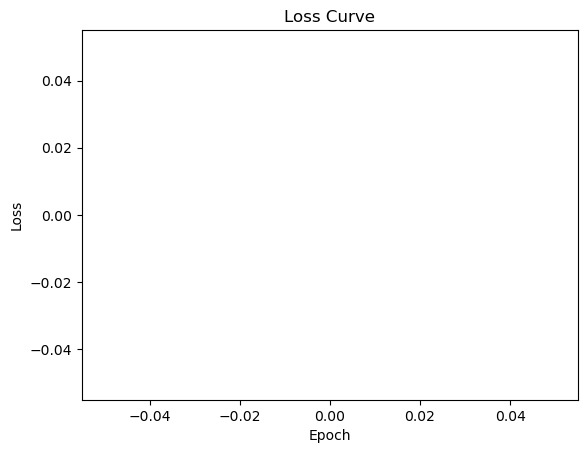

Epoch: 1, Loss: 0.9918878533024242 + 0.0im
Epoch: 2, Loss: 2.3567616698629155 + 0.0im
Epoch: 3, Loss: 1.1855919296574986 + 0.0im
Epoch: 4, Loss: 1.9426350217386446 + 0.0im
Epoch: 5, Loss: 1.2775306094669545 + 0.0im
Epoch: 6, Loss: 1.5025340125863067 + 0.0im
Epoch: 7, Loss: 1.431532863503561 + 0.0im
Epoch: 8, Loss: 1.0159486800189392 + 0.0im
Epoch: 9, Loss: 0.9015089444728549 + 0.0im
Epoch: 10, Loss: 0.7761726032366859 + 0.0im
Epoch: 11, Loss: 0.7540189908846999 + 0.0im
Epoch: 12, Loss: 0.6858793761135245 + 0.0im
Epoch: 13, Loss: 0.6410150400882119 + 0.0im
Epoch: 14, Loss: 0.5943781726487973 + 0.0im
Epoch: 15, Loss: 0.5408260957985317 + 0.0im
Epoch: 16, Loss: 0.48831921918701704 + 0.0im
Epoch: 17, Loss: 0.4505200468638695 + 0.0im
Epoch: 18, Loss: 0.4123999818782467 + 0.0im
Epoch: 19, Loss: 0.36426946347634614 + 0.0im
Epoch: 20, Loss: 0.34942763978242136 + 0.0im
Epoch: 21, Loss: 0.31919557008989363 + 0.0im
Epoch: 22, Loss: 0.2751861756575076 + 0.0im
Epoch: 23, Loss: 0.25718131399092203 +

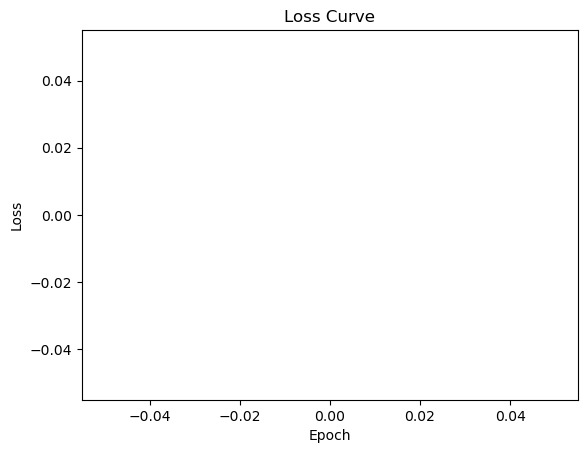

Epoch: 1, Loss: 0.2494589367858233 + 0.0im
Epoch: 2, Loss: 3.7211925201454177 + 0.0im
Epoch: 3, Loss: 1.0784566801194235 + 0.0im
Epoch: 4, Loss: 7.018243872333521 + 0.0im
Epoch: 5, Loss: 1.7123882069978094 + 0.0im
Epoch: 6, Loss: 2.3413799730478893 + 0.0im
Epoch: 7, Loss: 4.031044365149754 + 0.0im
Epoch: 8, Loss: 2.470044278409419 + 0.0im
Epoch: 9, Loss: 1.3536497682557493 + 0.0im
Epoch: 10, Loss: 1.5683498589079252 + 0.0im
Epoch: 11, Loss: 1.8738578774462349 + 0.0im
Epoch: 12, Loss: 1.7267766250785586 + 0.0im
Epoch: 13, Loss: 1.3196601865547133 + 0.0im
Epoch: 14, Loss: 1.0639155883630063 + 0.0im
Epoch: 15, Loss: 0.9990763048460128 + 0.0im
Epoch: 16, Loss: 0.9248072354947573 + 0.0im
Epoch: 17, Loss: 0.8045862472240938 + 0.0im
Epoch: 18, Loss: 0.7465661035880956 + 0.0im
Epoch: 19, Loss: 0.7015034234059625 + 0.0im
Epoch: 20, Loss: 0.6304798454733743 + 0.0im
Epoch: 21, Loss: 0.5525423569232698 + 0.0im
Epoch: 22, Loss: 0.4888724073176914 + 0.0im
Epoch: 23, Loss: 0.46630063007477884 + 0.0im

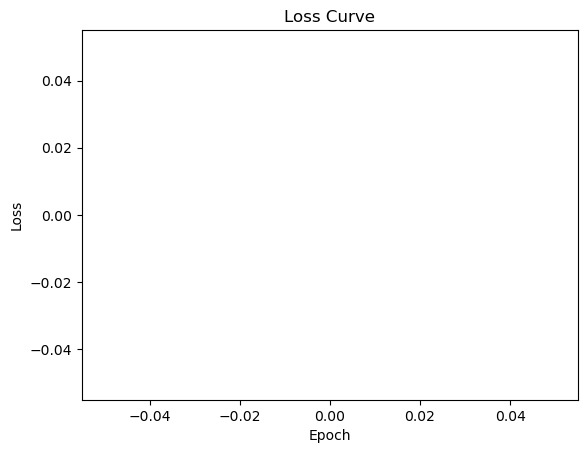

Epoch: 1, Loss: 0.24223503029789595 + 0.0im
Epoch: 2, Loss: 4.913387703859306 + 0.0im
Epoch: 3, Loss: 0.9839755453057775 + 0.0im
Epoch: 4, Loss: 8.457711378421504 + 0.0im
Epoch: 5, Loss: 1.9739412665462313 + 0.0im
Epoch: 6, Loss: 2.9245049884027754 + 0.0im
Epoch: 7, Loss: 4.010180329576349 + 0.0im
Epoch: 8, Loss: 2.347596663029058 + 0.0im
Epoch: 9, Loss: 1.6403164810044448 + 0.0im
Epoch: 10, Loss: 2.2330664293938214 + 0.0im
Epoch: 11, Loss: 2.4131943326488288 + 0.0im
Epoch: 12, Loss: 1.5604181747657546 + 0.0im
Epoch: 13, Loss: 1.5650121279739797 + 0.0im
Epoch: 14, Loss: 1.5147483050307133 + 0.0im
Epoch: 15, Loss: 1.1651766291679957 + 0.0im
Epoch: 16, Loss: 1.0127180811544723 + 0.0im
Epoch: 17, Loss: 0.9684017028197248 + 0.0im
Epoch: 18, Loss: 0.791501666098549 + 0.0im
Epoch: 19, Loss: 0.6549422847289497 + 0.0im
Epoch: 20, Loss: 0.6159719660788321 + 0.0im
Epoch: 21, Loss: 0.6163177399757505 + 0.0im
Epoch: 22, Loss: 0.5520795859866298 + 0.0im
Epoch: 23, Loss: 0.48033749133414355 + 0.0im


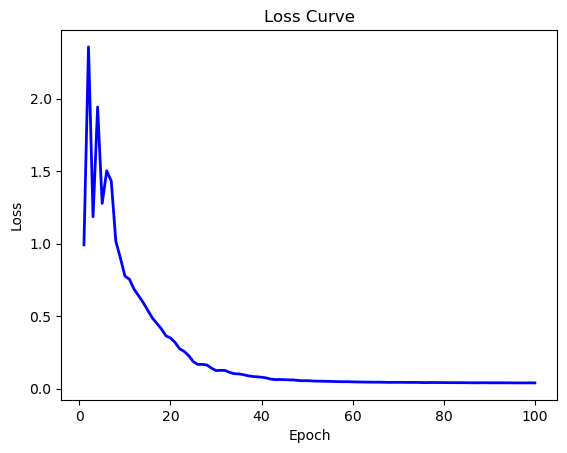

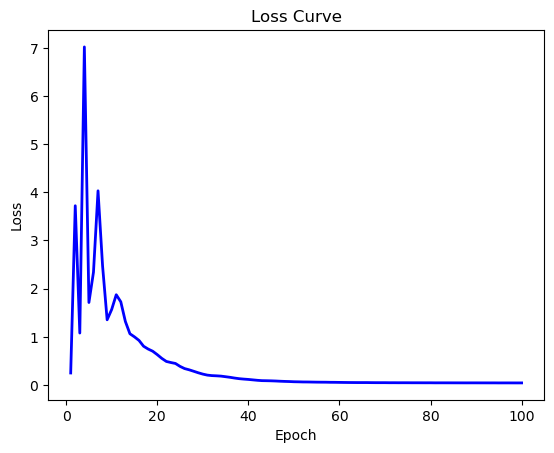

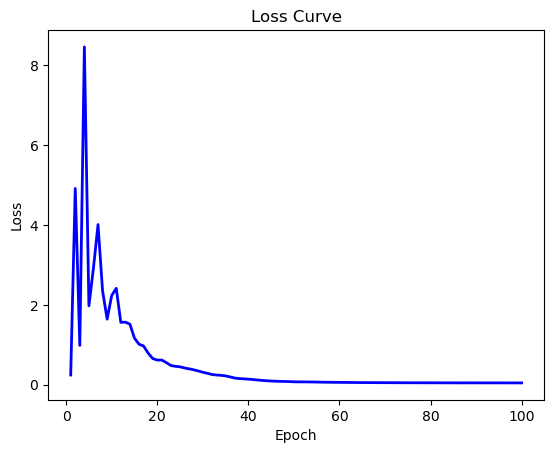

In [15]:
for i in (0.1,0.01,0.001)
    
    layer1=CPTC_Layer(hop,deepcopy(W1))
    Norm=complexNormLayer()
    layer2=PTC_Layer(hop,deepcopy(W2))
    act=Softmax()
    layer1=test_Layer(layer1,sqrt(length(x)),t , act,true)
    layers=[layer1,Norm,layer2]

    layer1.V.W = layer1.V.W*i
    layer1.K.W = layer1.K.W*i
    layer1.Q.W = layer1.Q.W*i
    layer2.W = layer2.W*i
    train(opt,layers,x,t,D,epochs=100)
end 

In [10]:
# train(opt,layers,x,t,D,epochs=1500)

In [11]:
train(opt,layers,x,t,D,epochs=1500)

LoadError: UndefVarError: `layers` not defined

In [ ]:
opt.α=0.01

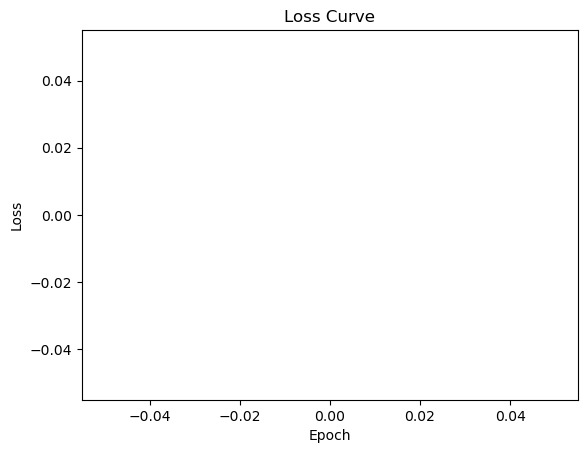

Epoch: 1, Loss: 0.0625229140167767 + 0.0im
Epoch: 2, Loss: 0.06262879319601368 + 0.0im
Epoch: 3, Loss: 0.06318501065316931 + 0.0im
Epoch: 4, Loss: 0.06228538516018625 + 0.0im
Epoch: 5, Loss: 0.06209704488745877 + 0.0im
Epoch: 6, Loss: 0.06161353369191669 + 0.0im
Epoch: 7, Loss: 0.06285525275996832 + 0.0im
Epoch: 8, Loss: 0.06231987692369329 + 0.0im
Epoch: 9, Loss: 0.06166480274190659 + 0.0im
Epoch: 10, Loss: 0.06247686458118645 + 0.0im
Epoch: 11, Loss: 0.06207865957479582 + 0.0im
Epoch: 12, Loss: 0.06230707265793716 + 0.0im
Epoch: 13, Loss: 0.06243514953637879 + 0.0im
Epoch: 14, Loss: 0.06222627524836514 + 0.0im
Epoch: 15, Loss: 0.06244258142717235 + 0.0im
Epoch: 16, Loss: 0.06236834308192356 + 0.0im
Epoch: 17, Loss: 0.0625777574794 + 0.0im
Epoch: 18, Loss: 0.06170322171420002 + 0.0im
Epoch: 19, Loss: 0.06264691281137236 + 0.0im
Epoch: 20, Loss: 0.06344479041418885 + 0.0im
Epoch: 21, Loss: 0.06289246725165273 + 0.0im
Epoch: 22, Loss: 0.062246688995338875 + 0.0im
Epoch: 23, Loss: 0.0624

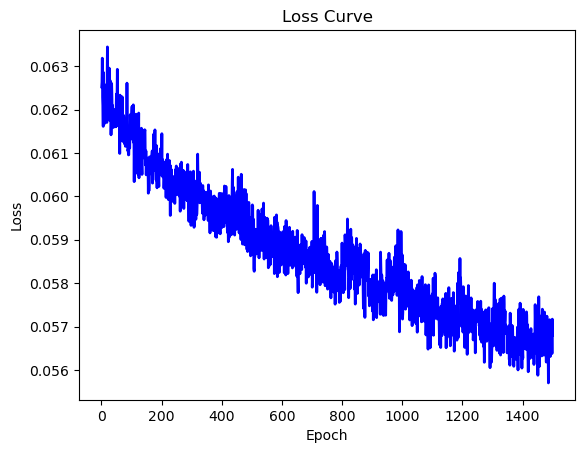

In [ ]:
train(opt,layers,x,t,D,epochs=1500)